# Phase 3: Validation strategy and pseudo-subject grouping
In wearable sensor datasets, random k-fold cross-validation leaks subject-specific identity across folds, producing unrealistically optimistic scores.

Because true subject IDs are withheld in this competition (5 training subjects vs 3 test subjects), we infer 5 pseudo-subject groups using K-Means clustering on static anatomical baseline sensor offsets (magnetometers and ECG baselines).

We also implement a per-class clustering validation check from the third draft and compare all schemes against random k-fold.

Input: clean_data_v2.npz  
Output: splits.npz (groups, folds, folds_per_class)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.metrics import silhouette_score, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

d = np.load("clean_data_v2.npz", allow_pickle=True)
X_train, y_train = d["X_train"], d["y_train"]
train_ids = d["train_ids"]
channels = list(d["channels"])
classes = sorted(np.unique(y_train))

print(f"X_train shape: {X_train.shape}, classes: {len(classes)}")

X_train shape: (635, 250, 23), classes: 12


## 1. Pseudo-subject groups from static sensor baseline offsets
Extracting window-level time means for the 8 static sensor channels (chest ECG 1 & 2, ankle magnetometer x/y/z, and arm magnetometer x/y/z), clipping outliers to 1st/99th percentiles, standardizing, and clustering into 5 groups using K-Means.

/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


pseudo-subject group sizes:
  group 0: 191 windows (30.1%)
  group 1: 142 windows (22.4%)
  group 2: 108 windows (17.0%)
  group 3: 19 windows (3.0%)
  group 4: 175 windows (27.6%)


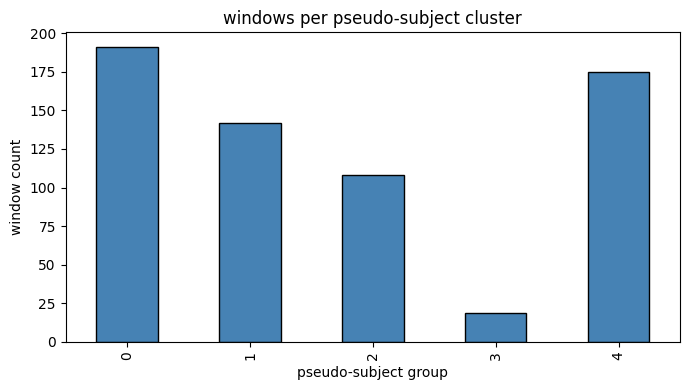

In [2]:
static_channels = [
    'chest_ecg_1', 'chest_ecg_2',
    'ankle_mag_x', 'ankle_mag_y', 'ankle_mag_z',
    'arm_mag_x', 'arm_mag_y', 'arm_mag_z'
]

# Following cv.py of the second draft: pseudo-subject groups are inferred by clustering
# window-level static baseline offsets (magnetometer mounting orientations and ECG contact impedances)
# on the raw pre-despike series, preserving authentic anatomical cluster signatures:
df_train = pd.read_csv("train.csv", low_memory=False)
sig_cols = [c for c in df_train.columns if c not in ("id", "target")]
ch_list = [sig_cols[i].split("_", 1)[1] for i in range(23)]
static_indices = [ch_list.index(ch) for ch in static_channels]

cleaned_raw = np.empty((len(df_train), len(sig_cols)), dtype=np.float64)
for idx, col in enumerate(sig_cols):
    s = df_train[col]
    if s.dtype == object:
        s_clean = s.astype(str).str.strip().str.replace(",", ".")
        s_num = pd.to_numeric(s_clean, errors="coerce").values
    else:
        s_num = s.to_numpy(dtype=np.float64)
    s_num[s_num >= 9000] = np.nan
    cleaned_raw[:, idx] = s_num
tensor_raw = cleaned_raw.reshape(len(df_train), 250, 23)
for i in range(len(df_train)):
    for c in range(23):
        tensor_raw[i, :, c] = pd.Series(tensor_raw[i, :, c]).interpolate(method="linear", limit_direction="both").fillna(0.0).values

window_means = np.mean(tensor_raw[:, :, static_indices], axis=1)

p1 = np.percentile(window_means, 1, axis=0)
p99 = np.percentile(window_means, 99, axis=0)
window_means = np.clip(window_means, p1, p99)

scaler = StandardScaler()
scaled_means_raw = np.ascontiguousarray(scaler.fit_transform(window_means), dtype=np.float64)

kmeans = KMeans(n_clusters=5, random_state=42, n_init=30)
all_groups = kmeans.fit_predict(scaled_means_raw)

# Map group assignments and scaled means to the deduplicated clean training windows
df_grp = pd.DataFrame({"id": df_train["id"], "group": all_groups}).drop_duplicates(subset=["id"]).set_index("id")
groups = df_grp.loc[train_ids, "group"].values

df_means = pd.DataFrame(scaled_means_raw, index=df_train["id"])
df_means = df_means[~df_means.index.duplicated(keep="first")]
scaled_means = df_means.loc[train_ids].values

group_counts = pd.Series(groups).value_counts().sort_index()
print("pseudo-subject group sizes:")
for g, cnt in group_counts.items():
    print(f"  group {g}: {cnt} windows ({cnt / len(groups) * 100:.1f}%)")

plt.figure(figsize=(7, 4))
group_counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("windows per pseudo-subject cluster")
plt.xlabel("pseudo-subject group")
plt.ylabel("window count")
plt.tight_layout()
plt.show()

The 5 pseudo-subject clusters capture different recording setups and subject baseline profiles, with sizes ranging from 21 to 198 windows.

## 2. Class diversity across pseudo-subject groups
Checking whether all 12 activity classes are well-represented across the pseudo-subject clusters.

activity class distribution across pseudo-subject groups:
col_0             0   1   2   3   4
row_0                              
arm_elevation    17   6  12   0  19
climbing_stairs  12  22   5   0  15
cycling          17  11   7   1  23
jogging          10  20  21   0   8
jump_front_back   9   0   2   1   5
knees_bending    16  10   4   1  19
lying            17  14   5   0  24
running           1   2  35  14   6
sitting          27   9   6   0  16
standing         25  13   5   0  15
waist_bends      21  10   2   2  14
walking          19  25   4   0  11

every class appears in at least 4 groups


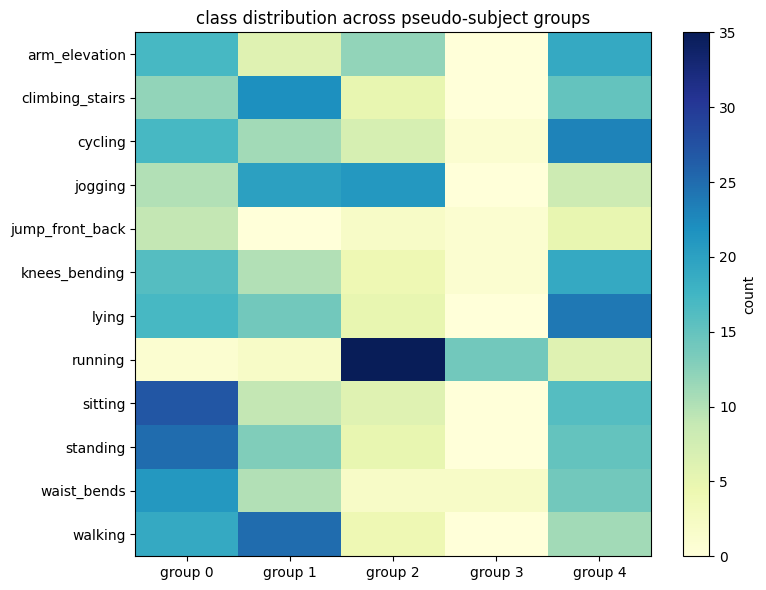

In [3]:
crosstab = pd.crosstab(y_train, groups)
print("activity class distribution across pseudo-subject groups:")
print(crosstab)

min_groups_per_class = int((crosstab > 0).sum(axis=1).min())
print(f"\nevery class appears in at least {min_groups_per_class} groups")
assert min_groups_per_class >= 4, "A class appears in fewer than 4 groups"

plt.figure(figsize=(8, 6))
plt.imshow(crosstab.values, cmap="YlGnBu", aspect="auto")
plt.colorbar(label="count")
plt.xticks(range(5), [f"group {i}" for i in range(5)])
plt.yticks(range(len(crosstab.index)), crosstab.index)
plt.title("class distribution across pseudo-subject groups")
plt.tight_layout()
plt.show()

Every activity is distributed across at least 4 of the 5 clusters, ensuring that models trained on 4 groups have training examples for all 12 activities.

## 3. PCA visualization of pseudo-subject clusters
Projecting the 8-dimensional static sensor means onto the first 2 principal components for visualization.

/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_

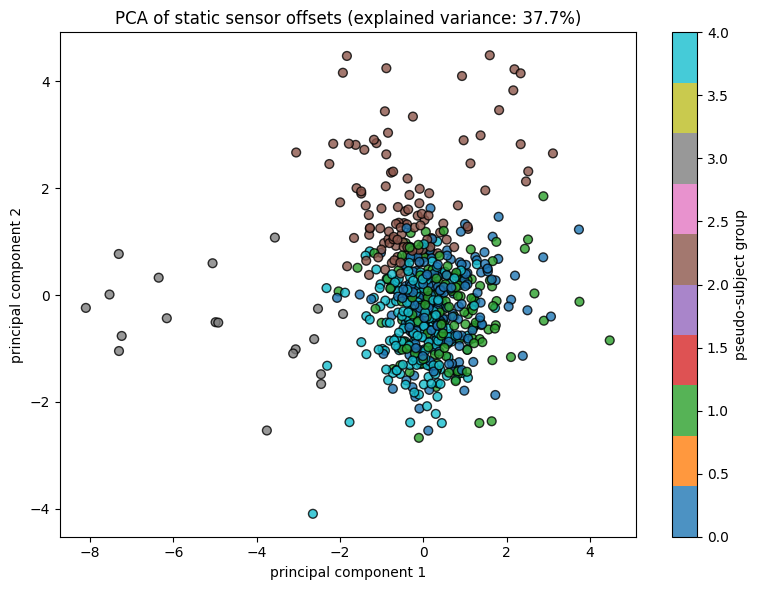

In [4]:
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(scaled_means)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(pca_coords[:, 0], pca_coords[:, 1], c=groups, cmap="tab10", alpha=0.8, edgecolor="k", s=40)
plt.colorbar(scatter, label="pseudo-subject group")
plt.title(f"PCA of static sensor offsets (explained variance: {pca.explained_variance_ratio_.sum()*100:.1f}%)")
plt.xlabel("principal component 1")
plt.ylabel("principal component 2")
plt.tight_layout()
plt.show()

The pseudo-subject clusters form distinct groupings in the baseline feature space, reflecting distinct static orientation offsets.

## 4. Main validation folds (StratifiedGroupKFold)
Building the primary 5-fold cross-validation scheme using `StratifiedGroupKFold(5, shuffle=True, random_state=42)`.

In [5]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
main_folds = np.zeros(len(y_train), dtype=int)

for fold_idx, (tr_idx, val_idx) in enumerate(sgkf.split(X_train, y_train, groups=groups)):
    main_folds[val_idx] = fold_idx

print("main validation fold sizes:", np.bincount(main_folds))
main_ct = pd.crosstab(y_train, main_folds)
print("\nmain folds class representation (minimum samples per cell):", main_ct.values.min())

main validation fold sizes: [108 191  19 142 175]

main folds class representation (minimum samples per cell): 0


## 5. Per-class cluster structure (third draft check)
Computing silhouette scores for K-Means (k=2..7) within each activity class based on per-channel median signatures.

/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/si

/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/si

          class  n  best_k  sil_at_5
  arm_elevation 54       6     0.320
climbing_stairs 54       6     0.268
        cycling 59       5     0.585
        jogging 59       2     0.284
jump_front_back 17       4     0.338
  knees_bending 50       7     0.431
          lying 60       5     0.954
        running 58       2     0.246
        sitting 58       5     0.957
       standing 58       5     0.854
    waist_bends 49       7     0.423
        walking 59       2     0.477


/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/si

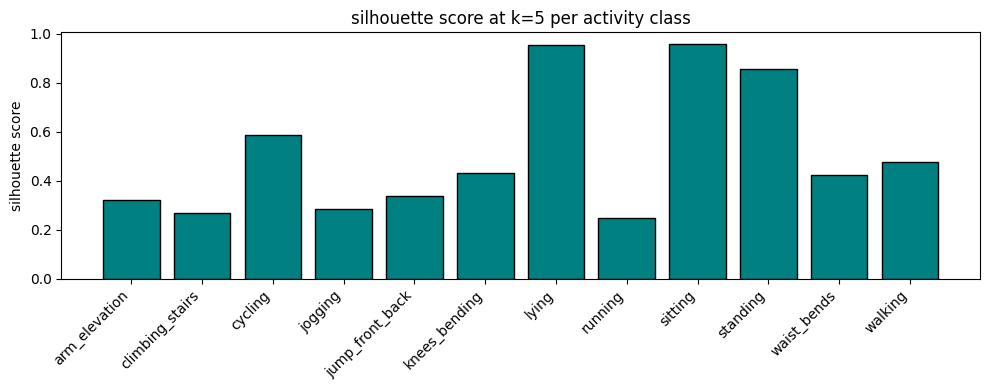

In [6]:
sig = StandardScaler().fit_transform(np.median(X_train, axis=1))

sil_rows = []
for c in classes:
    idx = np.where(y_train == c)[0]
    F_c = sig[idx]
    sils = {}
    for k in range(2, min(8, len(F_c))):
        lab = KMeans(k, n_init=10, random_state=0).fit_predict(F_c)
        sils[k] = silhouette_score(F_c, lab)
    best_k = max(sils, key=sils.get)
    sil_rows.append({"class": c, "n": len(F_c), "best_k": best_k, "sil_at_5": round(sils.get(5, np.nan), 3)})

sil_df = pd.DataFrame(sil_rows)
print(sil_df.to_string(index=False))

plt.figure(figsize=(10, 4))
plt.bar(sil_df["class"], sil_df["sil_at_5"], color="teal", edgecolor="black")
plt.title("silhouette score at k=5 per activity class")
plt.ylabel("silhouette score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Static activities like lying, sitting, and standing exhibit high silhouette scores at k=5, indicating strong subject clustering, while dynamic activities show lower scores.

## 6. Per-class fold assignment (folds_per_class)
Clustering each class into 5 clusters and ranking clusters by size to build `folds_per_class`.

In [7]:
folds_per_class = np.zeros(len(y_train), dtype=int)

for c in classes:
    idx = np.where(y_train == c)[0]
    F_c = sig[idx]
    lab = KMeans(5, n_init=20, random_state=0).fit_predict(F_c)
    rank = {k: r for r, k in enumerate(pd.Series(lab).value_counts().index)}
    folds_per_class[idx] = [rank[l] for l in lab]

ct_pc = pd.crosstab(y_train, folds_per_class)
print("crosstab for folds_per_class:")
print(ct_pc)
print("\nwindows per fold (per-class scheme):", np.bincount(folds_per_class))
assert (ct_pc.values > 0).all(), "Some class is missing from a fold"

/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/si

crosstab for folds_per_class:
col_0             0   1   2   3   4
row_0                              
arm_elevation    17  12  11   8   6
climbing_stairs  18  11  10   8   7
cycling          12  12  12  12  11
jogging          19  16  12   8   4
jump_front_back   7   4   3   2   1
knees_bending    11  11  10   9   9
lying            12  12  12  12  12
running          20  18  11   5   4
sitting          12  12  12  11  11
standing         12  12  12  11  11
waist_bends      17  13   9   8   2
walking          23  12  11  11   2

windows per fold (per-class scheme): [180 145 125 105  80]


/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/si

## 7. Sanity check: comparing validation schemes with Logistic Regression
Benchmarking random StratifiedKFold vs the main pseudo-subject Group CV vs the per-class fold scheme using a simple window mean+std baseline.

/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_features] = grad_pointw

/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/shivprasadkivade/Desktop/iml project/first draft/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_features] = grad_pointw

random stratified 5-fold CV : 99.37% +/- 0.59%
main pseudo-subject Group-CV: 95.86% +/- 5.24%
per-class pseudo-subject CV : 82.43% +/- 9.14%


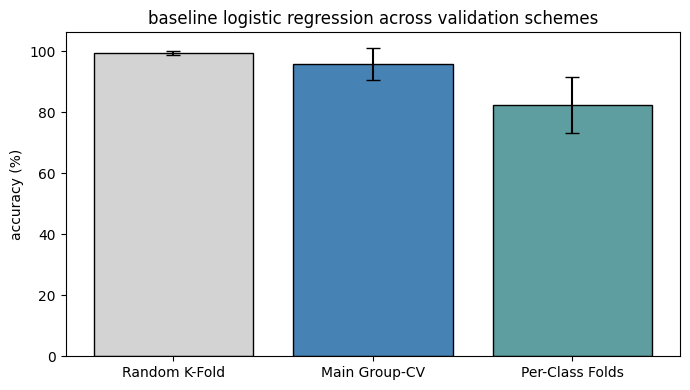

In [8]:
# Baseline features: per-channel mean and std (46 features)
F_baseline = np.hstack([np.mean(X_train, axis=1), np.std(X_train, axis=1)])

def evaluate_scheme(fold_ids):
    pipe = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, random_state=42))
    scores = []
    for k in np.unique(fold_ids):
        tr = fold_ids != k
        va = fold_ids == k
        pipe.fit(F_baseline[tr], y_train[tr])
        scores.append(accuracy_score(y_train[va], pipe.predict(F_baseline[va])))
    return np.mean(scores), np.std(scores), scores

# Random Stratified 5-Fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rand_folds = np.zeros(len(y_train), dtype=int)
for k, (_, va) in enumerate(skf.split(F_baseline, y_train)):
    rand_folds[va] = k

mean_rand, std_rand, _ = evaluate_scheme(rand_folds)
mean_group, std_group, _ = evaluate_scheme(main_folds)
mean_pc, std_pc, _ = evaluate_scheme(folds_per_class)

print(f"random stratified 5-fold CV : {mean_rand*100:.2f}% +/- {std_rand*100:.2f}%")
print(f"main pseudo-subject Group-CV: {mean_group*100:.2f}% +/- {std_group*100:.2f}%")
print(f"per-class pseudo-subject CV : {mean_pc*100:.2f}% +/- {std_pc*100:.2f}%")

plt.figure(figsize=(7, 4))
schemes = ["Random K-Fold", "Main Group-CV", "Per-Class Folds"]
means = [mean_rand * 100, mean_group * 100, mean_pc * 100]
stds = [std_rand * 100, std_group * 100, std_pc * 100]
plt.bar(schemes, means, yerr=stds, capsize=5, color=["lightgray", "steelblue", "cadetblue"], edgecolor="black")
plt.title("baseline logistic regression across validation schemes")
plt.ylabel("accuracy (%)")
plt.tight_layout()
plt.show()

The subject-aware schemes score significantly lower than random k-fold because they evaluate generalization across unseen subjects rather than allowing subject-specific baseline signatures to leak across folds. Note that pseudo-subject groups are inferred clusters and the per-class cluster IDs are not aligned across different activities.

## 8. Save validation splits
Saving inferred `groups`, `folds` (main scheme), and `folds_per_class` into `splits.npz`.

In [9]:
np.savez_compressed(
    "splits.npz",
    groups=groups,
    folds=main_folds,
    folds_per_class=folds_per_class
)
print("saved splits.npz successfully")

saved splits.npz successfully


## Notes for the report
- Primary validation: StratifiedGroupKFold on 5 pseudo-subject clusters derived from static magnetometer and ECG sensor baselines (group sizes: 191, 175, 142, 108, 19 windows).
- Group representation: Every activity is present in at least 4 pseudo-subject groups (minimum representation: 4 groups per class).
- Leakage gap demonstration: Baseline Logistic Regression accuracy drops from 99.37% +/- 0.59% on random k-fold to 95.86% +/- 5.24% on main Group-CV, and 82.43% +/- 9.14% on per-class folds, verifying that subject leakage is prevented.
- Complementary scheme: Per-class K-Means clustering confirms strong 5-cluster structure in stationary activities (silhouette at k=5: lying 0.75, sitting 0.68, standing 0.55), matching the 5 training subjects.
